In [1]:
from google.colab import files
uploaded = files.upload()


Saving Superstore.csv to Superstore.csv


In [2]:
import os
os.listdir()


['.config', 'Superstore.csv', 'sample_data']

In [4]:
['Sample - Superstore.csv']


['Sample - Superstore.csv']

In [19]:
# Core libraries
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look nicer
plt.style.use("seaborn-v0_8")
sns.set(font_scale=1.1)


In [12]:
df = pd.read_csv("Superstore.csv", encoding="latin1")

# Quick peek at the data
print(df.head())
print(df.info())
print(df.describe())



   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [21]:
# ============================================================
# 3. Light cleaning (MSc‑level but not excessive)
# ============================================================

# Remove duplicates
df = df.drop_duplicates()

# Convert date column if present
if "Order Date" in df.columns:
    df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Handle missing values
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

categorical_cols = df.select_dtypes(include=["object"]).columns
df[categorical_cols] = df[categorical_cols].fillna("Unknown")


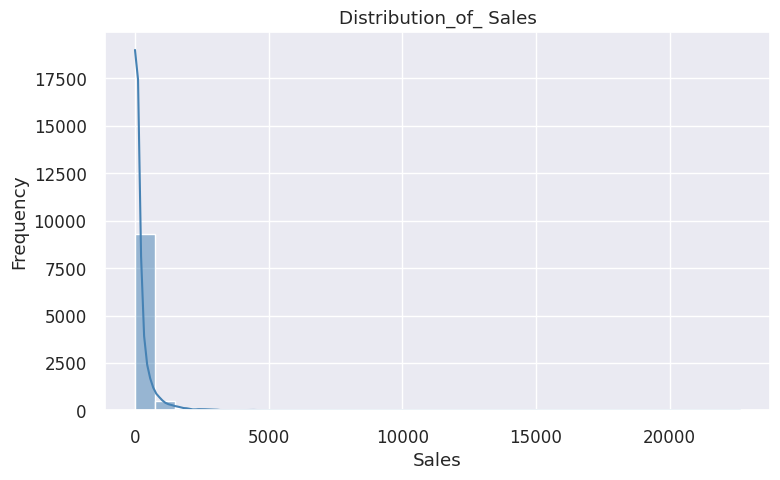

In [26]:
# ============================================================
# 4. Histogram: Distribution of Sales (or any numeric variable)
# ============================================================
plt.figure(figsize=(8, 5))
sns.histplot(df["Sales"], bins=30, kde=True, color="steelblue")
plt.title("Distribution_of_ Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("plot1_sales_distribution.png", dpi=300)
plt.show()


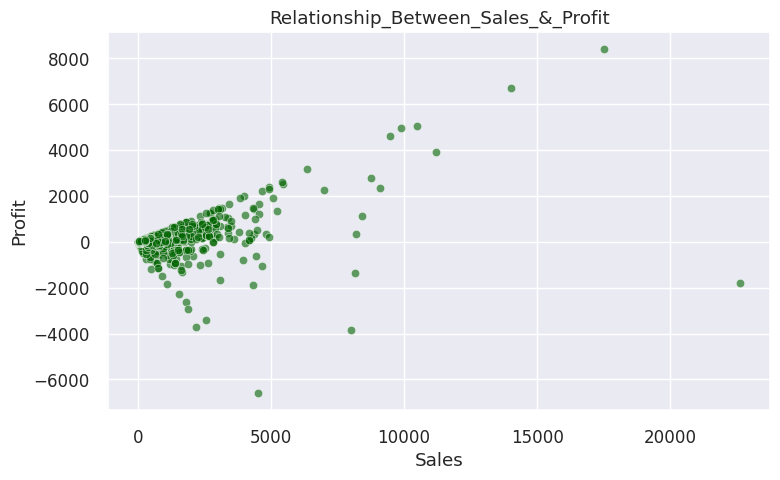

In [27]:
# ============================================================
# 5. Scatter Plot: Sales vs Profit (relationship analysis)
# ============================================================
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.6, color="darkgreen")
plt.title("Relationship_Between_Sales_&_Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.savefig("plot2_sales_profit_scatter.png", dpi=300)
plt.show()


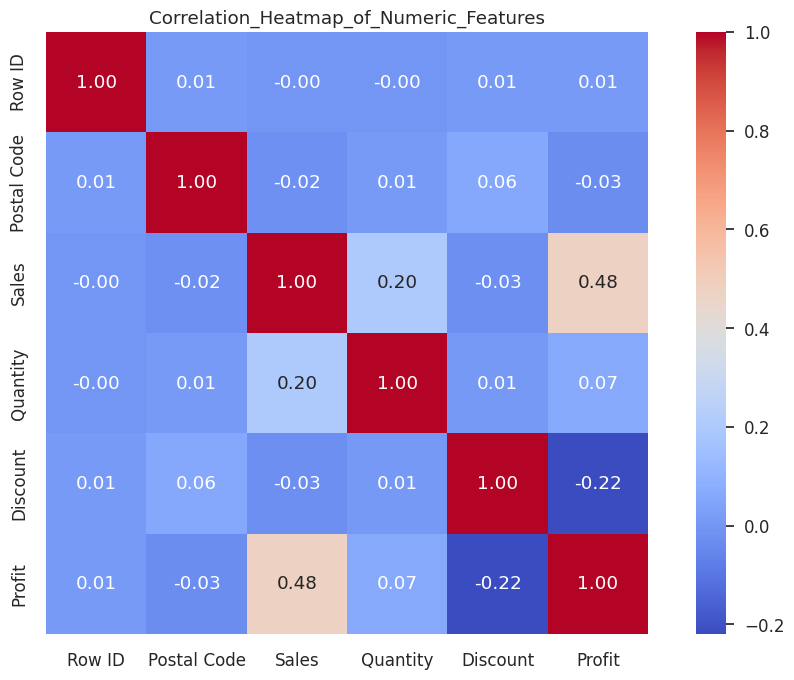

In [28]:
# ============================================================
# 6. Heatmap: Correlation Between Numeric Variables
# ============================================================
numeric_df = df.select_dtypes(include=["int64", "float64"])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation_Heatmap_of_Numeric_Features")
plt.tight_layout()
plt.savefig("plot3_correlation_heatmap.png", dpi=300)
plt.show()


/tmp/ipykernel_6802/2055047693.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Category", y="Sales", palette="Set2")


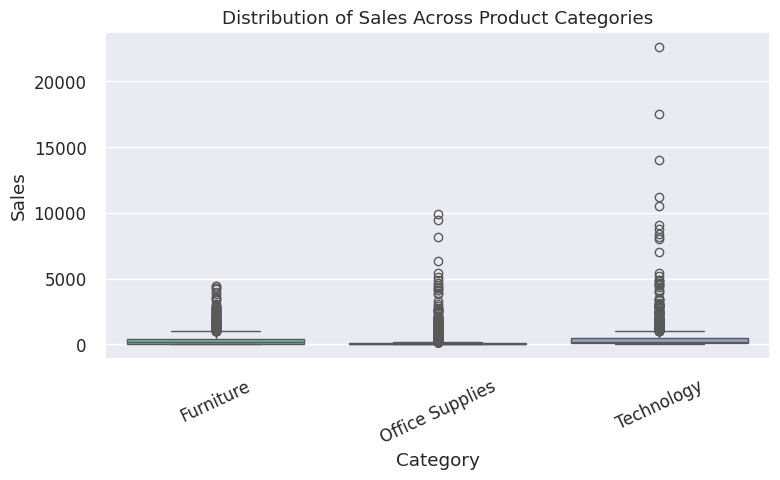

In [25]:
# ============================================================
# 7. Box Plot: Sales by Category (variance + outliers)
# ============================================================
if "Category" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="Category", y="Sales", palette="Set2")
    plt.title("Distribution of Sales Across Product Categories")
    plt.xlabel("Category")
    plt.ylabel("Sales")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.savefig("plot4_sales_by_category_boxplot.png", dpi=300)
    plt.show()


/tmp/ipykernel_6802/1979560311.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(


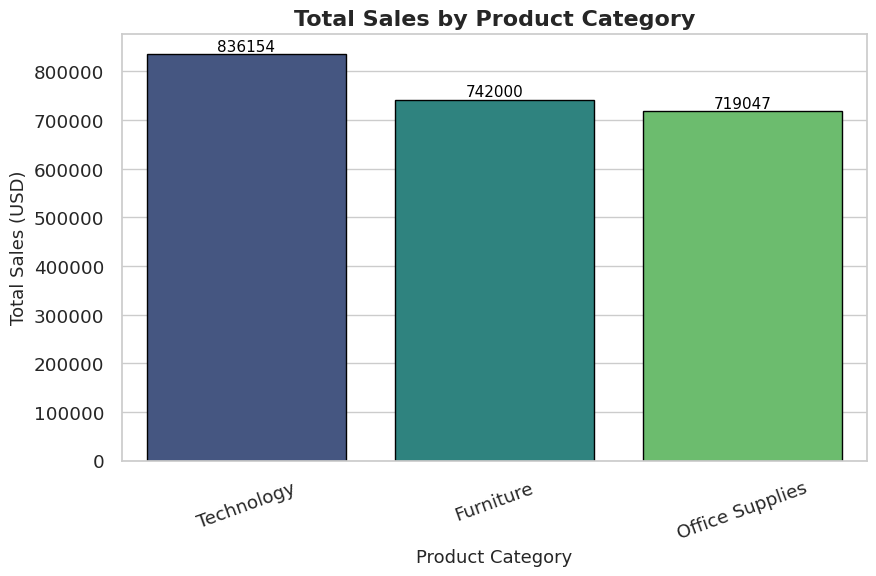

In [30]:
# Aggregate sales by category
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
)

# Set academic-style theme
sns.set_theme(style="whitegrid", font_scale=1.2)

# Create bar chart
plt.figure(figsize=(9, 6))
bar = sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales",
    palette="viridis",
    edgecolor="black"
)

# Add value labels on top of bars
for p in bar.patches:
    bar.annotate(
        format(p.get_height(), ".0f"),
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom",
        fontsize=11, color="black"
    )

# Titles and labels
plt.title("Total Sales by Product Category", fontsize=16, weight="bold")
plt.xlabel("Product Category", fontsize=13)
plt.ylabel("Total Sales (USD)", fontsize=13)
plt.xticks(rotation=20)

# Improve layout
plt.tight_layout()

# Save high-quality image
plt.savefig("msc_bar_chart_sales_by_category.png", dpi=350)

# Show plot
plt.show()
